In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torchvision.models import resnet18
import torch.nn.utils.prune as prune
from torch.utils.data import DataLoader, Subset, random_split
import copy
import numpy as np
import os
import sys
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
import json


In [23]:

### CONFIG ###
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# sim settings
FED_ROUNDS = 20           
TOTAL_CLIENTS = 5
CLIENTS_PER_ROUND = 5     
LOCAL_EPOCHS = 3
LOCAL_EPOCHS_FEDDF = 5
SERVER_FUSION_EPOCHS = 3
BATCH_SIZE = 512 
CLIENT_LR = 0.005
SERVER_LR = 0.0001
NUM_WORKERS = 8

# distillation 
TEMP = 2.0
ALPHA = 0.5
BETA = 0.5



PATH_BASELINE = 'resnet18_best.pth'
PATH_STUDENT = 'big_student_distilled_best.pth'

SAVE_DIR = (
    r"C:\Users\hoodo\Desktop\universitas\bachelor\BACHELORfinal"
    if os.name == "nt"
    else "/mnt/c/Users/hoodo/Desktop/universitas/bachelor/BACHELORfinal"
)
os.makedirs(SAVE_DIR, exist_ok=True)



In [3]:

######### MODEL DEFINITIONS ########
# models defined in part 1
from torchvision.models.resnet import ResNet, BasicBlock

def get_teacher_model():
    model = resnet18(num_classes=10)
    model.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
    model.maxpool = nn.Identity()
    return model


class Resnet14(ResNet):
    def __init__(self, num_classes=10):
        super().__init__(BasicBlock,[2, 2, 2, 2], num_classes=num_classes)
        
        # Deleting 4th stage 
        del self.layer4 
        
        self.fc = nn.Linear(256 * BasicBlock.expansion, num_classes)

    def _forward_impl(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        # here I skip layer 4

        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)
        return x


############### HELPERS ###################


def get_model_size_mb(model): #gets real model size 
    param_size = 0
    for param in model.parameters():
        param_size += param.nelement() * param.element_size()
    for buffer in model.buffers():
        param_size += buffer.nelement() * buffer.element_size()
    return param_size / 1e6

def get_compressed_size_mb(model): #simulates compressed model size
    total_nonzero = 0
    for name, param in model.named_parameters():
        if 'weight' in name:
            tensor = param.data.cpu()
            nonzero = torch.count_nonzero(tensor).item()
            total_nonzero += nonzero
        else:
            total_nonzero += param.nelement()
            
    return (total_nonzero * 1) / 1e6 


def apply_adaptive_pruning(model, amount):
    if amount <= 0: return model
    parameters_to_prune = []
    for name, module in model.named_modules():
        if isinstance(module, (nn.Conv2d, nn.Linear)):
            parameters_to_prune.append((module, 'weight'))

    prune.global_unstructured(
        parameters_to_prune,
        pruning_method=prune.L1Unstructured,
        amount=amount,
    )
    for module, _ in parameters_to_prune:
        prune.remove(module, 'weight')
    return model

def distillation_loss(student_logits, teacher_logits, T=2.0):
    soft_targets = F.softmax(teacher_logits / T, dim=-1)
    soft_prob = F.log_softmax(student_logits / T, dim=-1)
    return nn.KLDivLoss(reduction='batchmean')(soft_prob, soft_targets) * (T**2)

def evaluate(model, loader, device):
    model.eval()
    correct = 0; total = 0
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total

def federated_averaging(models):
    w_avg = copy.deepcopy(models[0].state_dict())
    for k in w_avg.keys():
        for i in range(1, len(models)):
            w_avg[k] += models[i].state_dict()[k]
        w_avg[k] = torch.div(w_avg[k], len(models))
    return w_avg

In [ ]:
def run_feddf(client_loaders, proxy_loader, test_loader, loader_for_name="iid"):
    print(f"\n Starting FedDF")
    
    global_model = get_teacher_model().to(device)
    if os.path.exists(PATH_BASELINE):
        global_model.load_state_dict(torch.load(PATH_BASELINE, map_location=device, weights_only=True))
    
    client_models = [Resnet14().to(device) for _ in range(TOTAL_CLIENTS)]
    if os.path.exists(PATH_STUDENT):
        state_dict = torch.load(PATH_STUDENT, map_location=device, weights_only=True)
        for m in client_models:
            m.load_state_dict(copy.deepcopy(state_dict), strict=False)
            
    history = []
    comm_history = []
    client_acc_history = {i: [] for i in range(TOTAL_CLIENTS)} 
    total_uplink_mb = 0
    highest_acc = 0.0

    model_size = get_model_size_mb(global_model)
    
    for round_idx in range(FED_ROUNDS):
        uploaded_models = []
        
        ###client phase
        for client_id in range(TOTAL_CLIENTS):
            student = client_models[client_id]
            student.train()
            optimizer = optim.SGD(student.parameters(), lr=CLIENT_LR, momentum=0.9)
            
            for _ in range(LOCAL_EPOCHS_FEDDF):
                for inputs, labels in client_loaders[client_id]:
                    inputs, labels = inputs.to(device), labels.to(device)
                    optimizer.zero_grad()
                    s_logits = student(inputs)
                    loss = F.cross_entropy(s_logits, labels)
                    loss.backward()
                    optimizer.step()
                    
            

            # Local model eval
            c_acc = evaluate(student, test_loader, device)
            client_acc_history[client_id].append(c_acc)
            
            # Size calc now simulates INT8 (1 byte per weight)
            total_uplink_mb += model_size
            uploaded_models.append(copy.deepcopy(student))
            
        ###server phase
        global_model.train()
        optimizer_server = optim.SGD(global_model.parameters(), lr=SERVER_LR, momentum=0.9)
        
        for m in uploaded_models: m.eval()
        
        limit_batches = 50
        for _ in range(SERVER_FUSION_EPOCHS):
            for batch_idx, (inputs, _) in enumerate(proxy_loader):
                if batch_idx >= limit_batches: break
                inputs = inputs.to(device)
                with torch.no_grad():
                    ensemble_logits = torch.zeros((inputs.size(0), 10), device=device)
                    for cm in uploaded_models:
                        ensemble_logits += cm(inputs)
                    ensemble_logits /= len(uploaded_models)
                
                server_logits = global_model(inputs)
                loss = distillation_loss(server_logits, ensemble_logits, TEMP)
                optimizer_server.zero_grad()
                loss.backward()
                optimizer_server.step()
                
        acc = evaluate(global_model, test_loader, device)
        history.append(acc)
        comm_history.append(total_uplink_mb)
        
        print(f" Round {round_idx+1}/{FED_ROUNDS}: Acc={acc:.2f}% | Uplink={total_uplink_mb:.2f} MB")
        if acc > highest_acc:
            highest_acc = acc
            torch.save(global_model.state_dict(), os.path.join(SAVE_DIR, f'feddf_basic_best_{loader_for_name}.pth'))
            for c_id, s_model in enumerate(client_models):
                torch.save(s_model.state_dict(), os.path.join(SAVE_DIR, f'feddf_basic_student_client{c_id}_best_{loader_for_name}.pth')
        del uploaded_models
        torch.cuda.empty_cache()

    histories_to_save = {
        "history": history,
        "comm_history": comm_history,
        "client_acc_history": client_acc_history,
        "total_uplink_mb": total_uplink_mb
    }
    with open(os.path.join(SAVE_DIR, f"feddf_basic_histories_{loader_for_name}.json"), "w") as f:
        json.dump(histories_to_save, f, indent=4)
        
    return history, total_uplink_mb, comm_history, client_acc_history

In [ ]:
def run_feddf_bidirect(client_loaders, proxy_loader, test_loader, loader_for_name="iid"):
    print(f"\n Starting bidirectional FedDF")
    
    global_model = get_teacher_model().to(device)
    if os.path.exists(PATH_BASELINE):
        global_model.load_state_dict(torch.load(PATH_BASELINE, map_location=device, weights_only=True))
    
    client_models = [Resnet14().to(device) for _ in range(TOTAL_CLIENTS)]
    if os.path.exists(PATH_STUDENT):
        state_dict = torch.load(PATH_STUDENT, map_location=device, weights_only=True)
        for m in client_models:
            m.load_state_dict(copy.deepcopy(state_dict), strict=False)
            
    history = []
    comm_history = []
    client_acc_history = {i: [] for i in range(TOTAL_CLIENTS)} 
    total_uplink_mb = 0
    highest_acc = 0.0

    model_size = get_model_size_mb(global_model)
    
    for round_idx in range(FED_ROUNDS):
        uploaded_models = []
        
        ###client phase
        for client_id in range(TOTAL_CLIENTS):
            teacher = global_model
            teacher.eval()
            student = client_models[client_id]
            student.train()
            optimizer = optim.SGD(student.parameters(), lr=CLIENT_LR, momentum=0.9)
            
            for _ in range(LOCAL_EPOCHS_FEDDF):
                for inputs, labels in client_loaders[client_id]:
                    inputs, labels = inputs.to(device), labels.to(device)
                    with torch.no_grad():
                        t_logits = teacher(inputs)
                    s_logits = student(inputs)
                    loss = ALPHA * F.cross_entropy(s_logits, labels) + BETA * distillation_loss(s_logits, t_logits, TEMP)
                    optimizer.zero_grad()
                    loss.backward()
                    optimizer.step()
                    

            # Local model eval
            c_acc = evaluate(student, test_loader, device)
            client_acc_history[client_id].append(c_acc)

            total_uplink_mb += model_size
            uploaded_models.append(student)
            
        ###server phase
        global_model.train()
        optimizer_server = optim.SGD(global_model.parameters(), lr=SERVER_LR, momentum=0.9)
        
        for m in uploaded_models: m.eval()
        
        limit_batches = 50
        for _ in range(SERVER_FUSION_EPOCHS):
            for batch_idx, (inputs, _) in enumerate(proxy_loader):
                if batch_idx >= limit_batches: break
                inputs = inputs.to(device)
                with torch.no_grad():
                    ensemble_logits = torch.zeros((inputs.size(0), 10), device=device)
                    for cm in uploaded_models:
                        ensemble_logits += cm(inputs)
                    ensemble_logits /= len(uploaded_models)
                
                server_logits = global_model(inputs)
                loss = distillation_loss(server_logits, ensemble_logits, TEMP)
                optimizer_server.zero_grad()
                loss.backward()
                optimizer_server.step()
                
        acc = evaluate(global_model, test_loader, device)
        history.append(acc)
        comm_history.append(total_uplink_mb)
        
        print(f" Round {round_idx+1}/{FED_ROUNDS}: Acc={acc:.2f}% | Uplink={total_uplink_mb:.2f} MB")
        if acc > highest_acc:
            highest_acc = acc
            torch.save(global_model.state_dict(), os.path.join(SAVE_DIR, f'feddf_bidir_best_{loader_for_name}.pth'))
            for c_id, s_model in enumerate(client_models):
                torch.save(s_model.state_dict(), os.path.join(SAVE_DIR, f'feddf_bidir_student_client{c_id}_best_{loader_for_name}.pth'))
        del uploaded_models
        torch.cuda.empty_cache()

    histories_to_save = {
        "history": history,
        "comm_history": comm_history,
        "client_acc_history": client_acc_history,
        "total_uplink_mb": total_uplink_mb
    }
    with open(os.path.join(SAVE_DIR, f"feddf_bidir_histories_{loader_for_name}.json"), "w") as f:
        json.dump(histories_to_save, f, indent=4)
        
    return history, total_uplink_mb, comm_history, client_acc_history

In [6]:
## DATA LOADING 
transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

trainSet = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
testSet = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

proxy_size = len(testSet) // 2
eval_size = len(testSet) - proxy_size
proxy_subset, eval_subset = random_split(testSet, [proxy_size, eval_size], generator=torch.Generator().manual_seed(42))


# Server Loaders
proxy_loader = DataLoader(proxy_subset, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True, num_workers=NUM_WORKERS, persistent_workers=True)
test_loader = DataLoader(eval_subset, batch_size=BATCH_SIZE, shuffle=False, pin_memory=True, num_workers=NUM_WORKERS, persistent_workers=True)

/home/cavey/feddf_stage2/.venv/lib/python3.12/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


In [7]:
## CLIENT DATA LOADING

#goal: number of items per client must differ, and number of items per class per each client too.

def dirichlet(dataset, n_clients, alpha):
    client_ids = [[] for _ in range(n_clients)]
    classes = np.array(dataset.targets)
    n_classes = len(np.unique(classes))

    for c in range(n_classes):

        class_proportions = np.random.dirichlet(np.repeat(alpha, n_clients))

        class_ids = np.where(classes == c)[0]
        np.random.shuffle(class_ids)
        ids_per_client = (class_proportions*len(class_ids)).astype(int)
        ids_per_client[-1] += len(class_ids) - ids_per_client.sum() #to avoid rounding errors

        split_ids = np.split(class_ids, np.cumsum(ids_per_client)[:-1])
        for i in range(n_clients):
            client_ids[i].extend(split_ids[i].tolist())

    return client_ids

# Client Loaders

client_loaders_iid = []
client_loaders_moderatedirichlet = []
client_loaders_strongdirichlet = []
client_ids_iid = list(range(len(trainSet)))
client_ids_moderatedirichlet = dirichlet(trainSet, TOTAL_CLIENTS, alpha=0.5)
client_ids_strongdirichlet = dirichlet(trainSet, TOTAL_CLIENTS, alpha=0.1)

#below is IID split:
split_size = len(trainSet) // TOTAL_CLIENTS
for i in range(TOTAL_CLIENTS):
    subset_indices = client_ids_iid[i*split_size : (i+1)*split_size]
    client_dataset = Subset(trainSet, subset_indices)
    client_loaders_iid.append(DataLoader(client_dataset, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True, num_workers=NUM_WORKERS, persistent_workers=True))


for i in range(TOTAL_CLIENTS):
    client_dataset_moderate = Subset(trainSet, client_ids_moderatedirichlet[i])
    client_loaders_moderatedirichlet.append(DataLoader(client_dataset_moderate, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True, num_workers=NUM_WORKERS, persistent_workers=True))
    client_dataset_strong = Subset(trainSet, client_ids_strongdirichlet[i])
    client_loaders_strongdirichlet.append(DataLoader(client_dataset_strong, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True, num_workers=NUM_WORKERS, persistent_workers=True))

    

In [8]:

def visualize_split(client_ids, dataset, num_classes=10):
    # Matrix to store counts: rows = clients, cols = classes
    split_matrix = np.zeros((len(client_ids), num_classes))
    targets = np.array(dataset.targets)
    
    # Count how many samples of each class belong to each client
    for i, indices in enumerate(client_ids):
        client_labels = targets[indices]
        unique_classes, counts = np.unique(client_labels, return_counts=True)
        for cls, count in zip(unique_classes, counts):
            split_matrix[i, cls] = count
            
    # Plotting the stacked bar chart
    fig, ax = plt.subplots(figsize=(12, 7))
    clients_x = np.arange(len(client_ids))
    
    bottom = np.zeros(len(client_ids))
    colors = plt.cm.tab10(np.linspace(0, 1, num_classes)) # Colors for 10 classes
    
    for cls in range(num_classes):
        ax.bar(clients_x, split_matrix[:, cls], bottom=bottom, 
               label=f'Class {cls}', color=colors[cls], edgecolor='white', linewidth=0.5)
        bottom += split_matrix[:, cls]
        
    ax.set_title(f'Dirichlet Non-IID Data Split (\u03b1=0.5)', fontsize=16, weight='bold')
    ax.set_xlabel('Client ID', fontsize=14)
    ax.set_ylabel('Total Number of Samples', fontsize=14)
    ax.set_xticks(clients_x)
    ax.set_xticklabels([f'Client {i+1}' for i in range(len(client_ids))])
    
    # Put legend outside the plot
    ax.legend(title='CIFAR-10 Classes', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()






###LLLM USED TO ASSIST WITH VISUALIZATION CODE

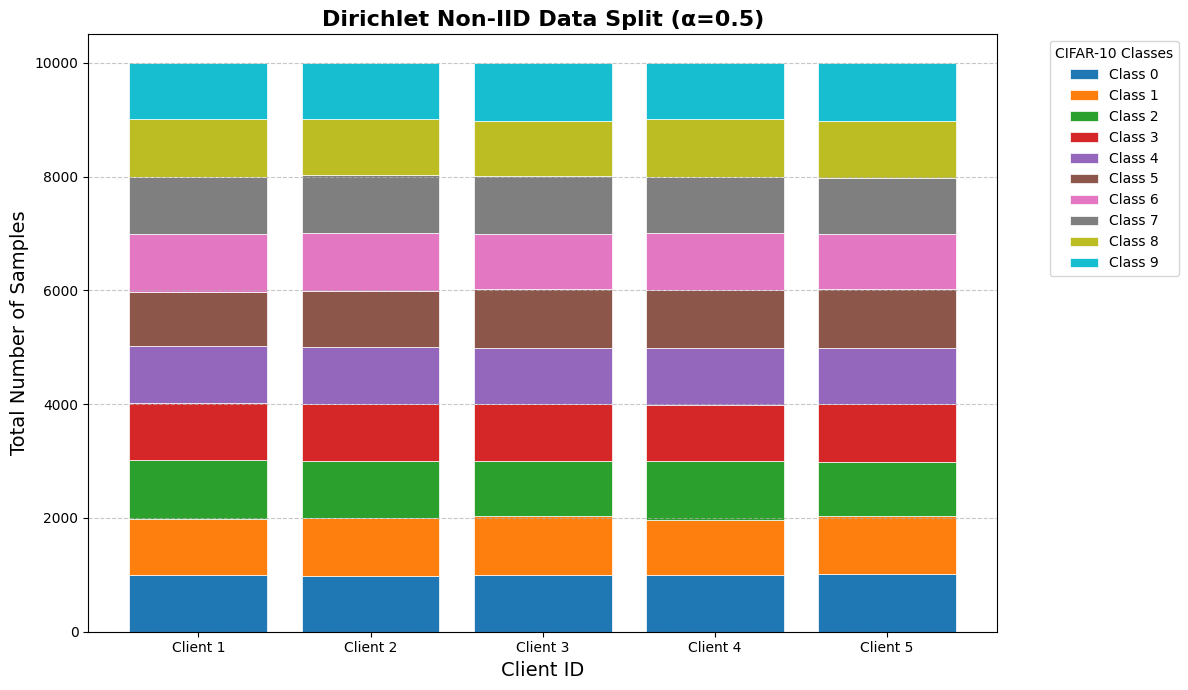

In [9]:
split_size = len(trainSet) // TOTAL_CLIENTS
client_ids_iid_chunks = [client_ids_iid[i*split_size : (i+1)*split_size] for i in range(TOTAL_CLIENTS)]

visualize_split(client_ids_iid_chunks, trainSet)

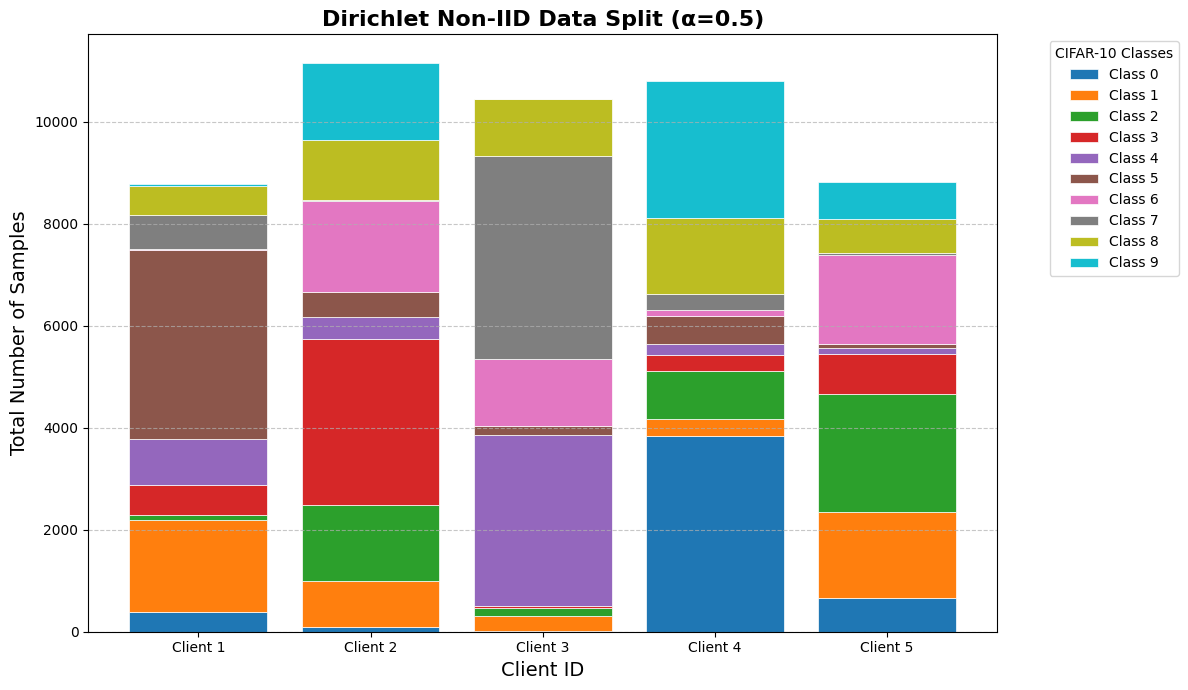

In [10]:
visualize_split(client_ids_moderatedirichlet, trainSet)

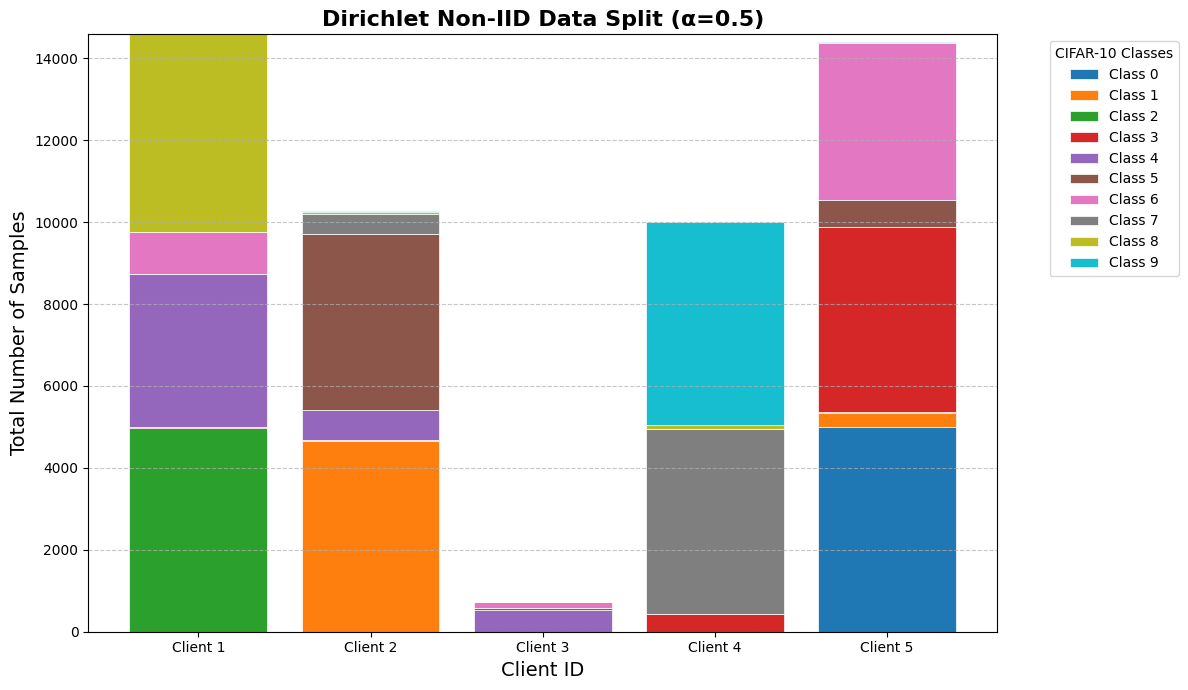

In [11]:
visualize_split(client_ids_strongdirichlet, trainSet)

//////////////
//////////////
/////////////

execution

/////////////
//////////////
///////////////


In [12]:
if __name__ == '__main__':
    feddf_iid_acc, feddf_iid_cost, feddf_iid_comm_hist, client_feddf_iid_acc_hist = run_feddf(client_loaders_iid, proxy_loader, test_loader, loader_for_name="iid")


 Starting FedDF
 Round 1/20: Acc=88.68% | Uplink=223.67 MB
 Round 2/20: Acc=88.46% | Uplink=447.34 MB
 Round 3/20: Acc=88.52% | Uplink=671.02 MB
 Round 4/20: Acc=88.42% | Uplink=894.69 MB
 Round 5/20: Acc=89.14% | Uplink=1118.36 MB
 Round 6/20: Acc=88.26% | Uplink=1342.03 MB
 Round 7/20: Acc=89.20% | Uplink=1565.70 MB
 Round 8/20: Acc=89.14% | Uplink=1789.38 MB
 Round 9/20: Acc=88.40% | Uplink=2013.05 MB
 Round 10/20: Acc=89.02% | Uplink=2236.72 MB
 Round 11/20: Acc=88.86% | Uplink=2460.39 MB
 Round 12/20: Acc=89.10% | Uplink=2684.06 MB
 Round 13/20: Acc=88.78% | Uplink=2907.74 MB
 Round 14/20: Acc=89.14% | Uplink=3131.41 MB
 Round 15/20: Acc=89.56% | Uplink=3355.08 MB
 Round 16/20: Acc=89.18% | Uplink=3578.75 MB
 Round 17/20: Acc=88.56% | Uplink=3802.42 MB
 Round 18/20: Acc=88.72% | Uplink=4026.10 MB
 Round 19/20: Acc=88.80% | Uplink=4249.77 MB
 Round 20/20: Acc=89.48% | Uplink=4473.44 MB


In [13]:
if __name__ == '__main__':
    feddf_mod_acc, feddf_mod_cost, feddf_mod_comm_hist, client_feddf_mod_acc_hist = run_feddf(client_loaders_moderatedirichlet, proxy_loader, test_loader, loader_for_name="moderatedirichlet")


 Starting FedDF
 Round 1/20: Acc=88.32% | Uplink=223.67 MB
 Round 2/20: Acc=88.28% | Uplink=447.34 MB
 Round 3/20: Acc=88.88% | Uplink=671.02 MB
 Round 4/20: Acc=88.62% | Uplink=894.69 MB
 Round 5/20: Acc=89.00% | Uplink=1118.36 MB
 Round 6/20: Acc=88.54% | Uplink=1342.03 MB
 Round 7/20: Acc=88.72% | Uplink=1565.70 MB
 Round 8/20: Acc=88.46% | Uplink=1789.38 MB
 Round 9/20: Acc=88.76% | Uplink=2013.05 MB
 Round 10/20: Acc=88.80% | Uplink=2236.72 MB
 Round 11/20: Acc=88.26% | Uplink=2460.39 MB
 Round 12/20: Acc=88.04% | Uplink=2684.06 MB
 Round 13/20: Acc=88.92% | Uplink=2907.74 MB
 Round 14/20: Acc=88.24% | Uplink=3131.41 MB
 Round 15/20: Acc=88.58% | Uplink=3355.08 MB
 Round 16/20: Acc=88.84% | Uplink=3578.75 MB
 Round 17/20: Acc=88.58% | Uplink=3802.42 MB
 Round 18/20: Acc=88.88% | Uplink=4026.10 MB
 Round 19/20: Acc=88.50% | Uplink=4249.77 MB
 Round 20/20: Acc=88.46% | Uplink=4473.44 MB


In [14]:
if __name__ == '__main__':
    feddf_strong_acc, feddf_strong_cost, feddf_strong_comm_hist, client_feddf_strong_acc_hist = run_feddf(client_loaders_strongdirichlet, proxy_loader, test_loader, loader_for_name="strongdirichlet")


 Starting FedDF
 Round 1/20: Acc=88.54% | Uplink=223.67 MB
 Round 2/20: Acc=88.56% | Uplink=447.34 MB
 Round 3/20: Acc=88.44% | Uplink=671.02 MB
 Round 4/20: Acc=88.58% | Uplink=894.69 MB
 Round 5/20: Acc=88.26% | Uplink=1118.36 MB
 Round 6/20: Acc=88.28% | Uplink=1342.03 MB
 Round 7/20: Acc=88.62% | Uplink=1565.70 MB
 Round 8/20: Acc=88.26% | Uplink=1789.38 MB
 Round 9/20: Acc=87.30% | Uplink=2013.05 MB
 Round 10/20: Acc=87.34% | Uplink=2236.72 MB
 Round 11/20: Acc=87.22% | Uplink=2460.39 MB
 Round 12/20: Acc=86.94% | Uplink=2684.06 MB
 Round 13/20: Acc=87.40% | Uplink=2907.74 MB
 Round 14/20: Acc=87.60% | Uplink=3131.41 MB
 Round 15/20: Acc=87.50% | Uplink=3355.08 MB
 Round 16/20: Acc=87.22% | Uplink=3578.75 MB
 Round 17/20: Acc=87.12% | Uplink=3802.42 MB
 Round 18/20: Acc=87.50% | Uplink=4026.10 MB
 Round 19/20: Acc=87.32% | Uplink=4249.77 MB
 Round 20/20: Acc=87.12% | Uplink=4473.44 MB


In [15]:
if __name__ == '__main__':
    bifeddf_iid_acc, bifeddf_iid_cost, bifeddf_iid_comm_hist, client_bifeddf_iid_acc_hist = run_feddf_bidirect(client_loaders_iid, proxy_loader, test_loader, loader_for_name="iid")


 Starting bidirectional FedDF
 Round 1/20: Acc=88.72% | Uplink=223.67 MB
 Round 2/20: Acc=88.64% | Uplink=447.34 MB
 Round 3/20: Acc=88.50% | Uplink=671.02 MB
 Round 4/20: Acc=88.56% | Uplink=894.69 MB
 Round 5/20: Acc=88.58% | Uplink=1118.36 MB
 Round 6/20: Acc=87.88% | Uplink=1342.03 MB
 Round 7/20: Acc=88.64% | Uplink=1565.70 MB
 Round 8/20: Acc=88.16% | Uplink=1789.38 MB
 Round 9/20: Acc=88.90% | Uplink=2013.05 MB
 Round 10/20: Acc=88.66% | Uplink=2236.72 MB
 Round 11/20: Acc=89.02% | Uplink=2460.39 MB
 Round 12/20: Acc=88.80% | Uplink=2684.06 MB
 Round 13/20: Acc=88.62% | Uplink=2907.74 MB
 Round 14/20: Acc=88.36% | Uplink=3131.41 MB
 Round 15/20: Acc=88.10% | Uplink=3355.08 MB
 Round 16/20: Acc=88.12% | Uplink=3578.75 MB
 Round 17/20: Acc=88.26% | Uplink=3802.42 MB
 Round 18/20: Acc=88.74% | Uplink=4026.10 MB
 Round 19/20: Acc=88.58% | Uplink=4249.77 MB
 Round 20/20: Acc=88.50% | Uplink=4473.44 MB


In [16]:
if __name__ == '__main__':
    bifeddf_mod_acc, bifeddf_mod_cost, bifeddf_mod_comm_hist, client_bifeddf_mod_acc_hist = run_feddf_bidirect(client_loaders_moderatedirichlet, proxy_loader, test_loader, loader_for_name="moderatedirichlet")


 Starting bidirectional FedDF
 Round 1/20: Acc=88.38% | Uplink=223.67 MB
 Round 2/20: Acc=88.20% | Uplink=447.34 MB
 Round 3/20: Acc=88.64% | Uplink=671.02 MB
 Round 4/20: Acc=88.50% | Uplink=894.69 MB
 Round 5/20: Acc=88.12% | Uplink=1118.36 MB
 Round 6/20: Acc=88.06% | Uplink=1342.03 MB
 Round 7/20: Acc=88.34% | Uplink=1565.70 MB
 Round 8/20: Acc=88.48% | Uplink=1789.38 MB
 Round 9/20: Acc=88.24% | Uplink=2013.05 MB
 Round 10/20: Acc=87.84% | Uplink=2236.72 MB
 Round 11/20: Acc=87.98% | Uplink=2460.39 MB
 Round 12/20: Acc=87.66% | Uplink=2684.06 MB
 Round 13/20: Acc=87.88% | Uplink=2907.74 MB
 Round 14/20: Acc=88.06% | Uplink=3131.41 MB
 Round 15/20: Acc=87.88% | Uplink=3355.08 MB
 Round 16/20: Acc=87.84% | Uplink=3578.75 MB
 Round 17/20: Acc=87.62% | Uplink=3802.42 MB
 Round 18/20: Acc=87.54% | Uplink=4026.10 MB
 Round 19/20: Acc=87.74% | Uplink=4249.77 MB
 Round 20/20: Acc=87.32% | Uplink=4473.44 MB


In [17]:
if __name__ == '__main__':
    bifeddf_strong_acc, bifeddf_strong_cost, bifeddf_strong_comm_hist, client_bifeddf_strong_acc_hist = run_feddf_bidirect(client_loaders_strongdirichlet, proxy_loader, test_loader, loader_for_name="strongdirichlet")


 Starting bidirectional FedDF
 Round 1/20: Acc=88.12% | Uplink=223.67 MB
 Round 2/20: Acc=88.18% | Uplink=447.34 MB
 Round 3/20: Acc=88.00% | Uplink=671.02 MB
 Round 4/20: Acc=87.86% | Uplink=894.69 MB
 Round 5/20: Acc=87.54% | Uplink=1118.36 MB
 Round 6/20: Acc=87.30% | Uplink=1342.03 MB
 Round 7/20: Acc=87.46% | Uplink=1565.70 MB
 Round 8/20: Acc=87.54% | Uplink=1789.38 MB
 Round 9/20: Acc=87.26% | Uplink=2013.05 MB
 Round 10/20: Acc=86.84% | Uplink=2236.72 MB
 Round 11/20: Acc=85.92% | Uplink=2460.39 MB
 Round 12/20: Acc=86.10% | Uplink=2684.06 MB
 Round 13/20: Acc=85.64% | Uplink=2907.74 MB
 Round 14/20: Acc=85.36% | Uplink=3131.41 MB
 Round 15/20: Acc=85.20% | Uplink=3355.08 MB
 Round 16/20: Acc=85.50% | Uplink=3578.75 MB
 Round 17/20: Acc=84.76% | Uplink=3802.42 MB
 Round 18/20: Acc=83.98% | Uplink=4026.10 MB
 Round 19/20: Acc=83.48% | Uplink=4249.77 MB
 Round 20/20: Acc=83.00% | Uplink=4473.44 MB


In [26]:
def load_saved_models_and_histories(run_prefix="feddf_basic", loader_name="iid", n_clients=5):

    global_model = get_teacher_model().to(device)
    global_path = os.path.join(SAVE_DIR, f'{run_prefix}_best_{loader_name}.pth')
    if os.path.exists(global_path):
        global_model.load_state_dict(torch.load(global_path, map_location=device, weights_only=True))
    else:
        print(f"no global model at {global_path}")

    # clients are Resnet14, NOT teacher
    client_models = [Resnet14().to(device) for _ in range(n_clients)]
    for c_id in range(n_clients):
        client_path = os.path.join(
            SAVE_DIR, f'{run_prefix}_student_client{c_id}_best_{loader_name}.pth'
        )
        if os.path.exists(client_path):
            client_models[c_id].load_state_dict(
                torch.load(client_path, map_location=device, weights_only=True)
            )
        else:
            print(f"no client {c_id} model at {client_path}")

    history, comm_history, client_acc_history = [], [], {}
    history_path = os.path.join(SAVE_DIR, f"{run_prefix}_histories_{loader_name}.json")

    if os.path.exists(history_path):
        with open(history_path, "r") as f:
            data = json.load(f)
            history = data.get("history", [])
            comm_history = data.get("comm_history", [])
            raw_client_acc = data.get("client_acc_history", {})
            client_acc_history = {int(k): v for k, v in raw_client_acc.items()}
        print("Models and histories loaded successfully.")
    else:
        print(f"no history found at {history_path}")

    return global_model, client_models, history, comm_history, client_acc_history

In [27]:

feddf_iid_model, clients_iid_models, feddf_iid_acc, feddf_iid_comm_hist, client_feddf_iid_acc_hist = load_saved_models_and_histories(run_prefix="feddf_basic", loader_name="iid")
feddf_mod_model, clients_mod_models, feddf_mod_acc, feddf_mod_comm_hist, client_feddf_mod_acc_hist = load_saved_models_and_histories(run_prefix="feddf_basic", loader_name="moderatedirichlet")
feddf_strong_model, clients_strong_models, feddf_strong_acc, feddf_strong_comm_hist, client_feddf_strong_acc_hist = load_saved_models_and_histories(run_prefix="feddf_basic", loader_name="strongdirichlet")
bifeddf_iid_model, clients_bidir_iid_models, bifeddf_iid_acc, bifeddf_iid_comm_hist, client_bifeddf_iid_acc_hist = load_saved_models_and_histories(run_prefix="feddf_bidir", loader_name="iid")
bifeddf_mod_model, clients_bidir_mod_models, bifeddf_mod_acc, bifeddf_mod_comm_hist, client_bifeddf_mod_acc_hist = load_saved_models_and_histories(run_prefix="feddf_bidir", loader_name="moderatedirichlet")
bifeddf_strong_model, clients_bidir_strong_models, bifeddf_strong_acc, bifeddf_strong_comm_hist, client_bifeddf_strong_acc_hist = load_saved_models_and_histories(run_prefix="feddf_bidir", loader_name="strongdirichlet")

Models and histories loaded successfully.
Models and histories loaded successfully.
Models and histories loaded successfully.
Models and histories loaded successfully.
Models and histories loaded successfully.
Models and histories loaded successfully.


In [28]:
print("\n" + "="*40)
print("FINAL COMPARISON REPORT")
print("="*40)
print(f"{'Metric':<20} | {'Value':<15} ")
print("-" * 56)
print(f"{'FedDF IID Accuracy':<30} | {feddf_iid_acc[-1]:.2f}%")
print(f"{'FedDF Mod Dirichlet Acc':<30} | {feddf_mod_acc[-1]:.2f}%")
print(f"{'FedDF Strong Dirichlet Acc':<30} | {feddf_strong_acc[-1]:.2f}%")
print(f"{'BiFedDF IID Accuracy':<30} | {bifeddf_iid_acc[-1]:.2f}%")
print(f"{'BiFedDF Mod Dirichlet Acc':<30} | {bifeddf_mod_acc[-1]:.2f}%")
print(f"{'BiFedDF Strong Dirichlet Acc':<30} | {bifeddf_strong_acc[-1]:.2f}%")



print("="*40)
    
# Save
df = pd.DataFrame({
    'Round': range(1, FED_ROUNDS + 1),
    'FedDF_iid_Acc': feddf_iid_acc,
    'FedDF_ModDir_Acc': feddf_mod_acc,
    'FedDF_StrongDir_Acc': feddf_strong_acc,
    'BiFedDF_iid_Acc': bifeddf_iid_acc,
    'BiFedDF_ModDir_Acc': bifeddf_mod_acc,
    'BiFedDF_StrongDir_Acc': bifeddf_strong_acc,

})
df.to_csv("stage3_comparison_results.csv", index=False)
print("Results saved to stage3_comparison_results.csv")


FINAL COMPARISON REPORT
Metric               | Value           
--------------------------------------------------------
FedDF IID Accuracy             | 89.48%
FedDF Mod Dirichlet Acc        | 88.46%
FedDF Strong Dirichlet Acc     | 87.12%
BiFedDF IID Accuracy           | 88.50%
BiFedDF Mod Dirichlet Acc      | 87.32%
BiFedDF Strong Dirichlet Acc   | 83.00%
Results saved to stage3_comparison_results.csv


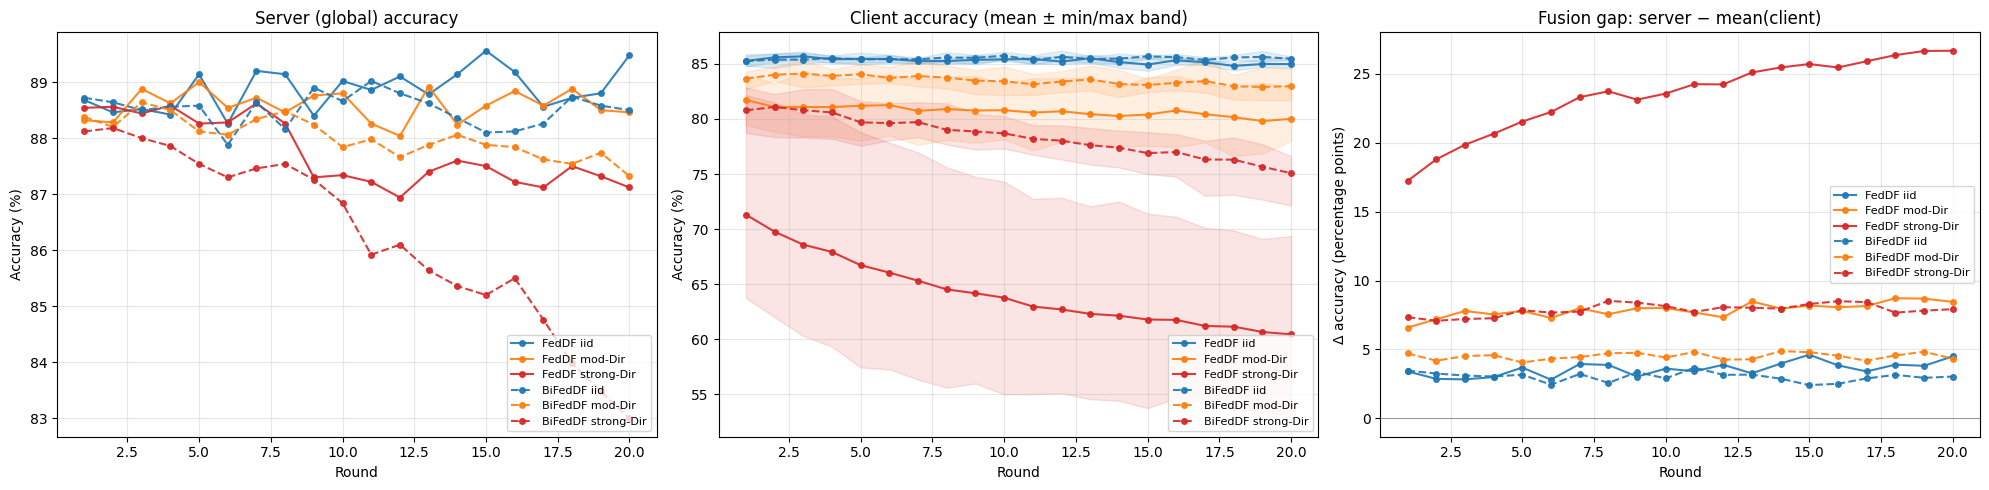

In [29]:
import numpy as np
import matplotlib.pyplot as plt

# (label, server_history, client_history_dict, color, linestyle)
runs = [
    ("FedDF iid",         feddf_iid_acc,      client_feddf_iid_acc_hist,    "tab:blue",   "-"),
    ("FedDF mod-Dir",     feddf_mod_acc,      client_feddf_mod_acc_hist,    "tab:orange", "-"),
    ("FedDF strong-Dir",  feddf_strong_acc,   client_feddf_strong_acc_hist, "tab:red",    "-"),
    ("BiFedDF iid",        bifeddf_iid_acc,    client_bifeddf_iid_acc_hist,    "tab:blue",   "--"),
    ("BiFedDF mod-Dir",    bifeddf_mod_acc,    client_bifeddf_mod_acc_hist,    "tab:orange", "--"),
    ("BiFedDF strong-Dir", bifeddf_strong_acc, client_bifeddf_strong_acc_hist, "tab:red",    "--"),
]

def _client_matrix(client_hist):
    # robust to int or str keys (json reload returns str keys)
    keys = sorted(client_hist.keys(), key=lambda k: int(k))
    return np.array([client_hist[k] for k in keys], dtype=float)  # (n_clients, n_rounds)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 5))

# 1) Server (global) accuracy across rounds
for name, server_hist, client_hist, color, ls in runs:
    if not server_hist:
        continue
    rounds = np.arange(1, len(server_hist) + 1)
    ax1.plot(rounds, server_hist, label=name, color=color, linestyle=ls,
             marker='o', markersize=4, alpha=0.9)
ax1.set_title("Server (global) accuracy")
ax1.set_xlabel("Round")
ax1.set_ylabel("Accuracy (%)")
ax1.grid(True, alpha=0.3)
ax1.legend(loc="lower right", fontsize=8)

# 2) Client accuracy: mean line + min/max band
for name, server_hist, client_hist, color, ls in runs:
    if not client_hist:
        continue
    arr = _client_matrix(client_hist)
    if arr.size == 0:
        continue
    rounds = np.arange(1, arr.shape[1] + 1)
    mean_acc = arr.mean(axis=0)
    min_acc  = arr.min(axis=0)
    max_acc  = arr.max(axis=0)
    ax2.plot(rounds, mean_acc, label=name, color=color, linestyle=ls,
             marker='o', markersize=4, alpha=0.9)
    ax2.fill_between(rounds, min_acc, max_acc, color=color, alpha=0.12)
ax2.set_title("Client accuracy (mean ± min/max band)")
ax2.set_xlabel("Round")
ax2.set_ylabel("Accuracy (%)")
ax2.grid(True, alpha=0.3)
ax2.legend(loc="lower right", fontsize=8)

# 3) Fusion gap: server - mean(client)
for name, server_hist, client_hist, color, ls in runs:
    if not server_hist or not client_hist:
        continue
    arr = _client_matrix(client_hist)
    n = min(len(server_hist), arr.shape[1])
    rounds = np.arange(1, n + 1)
    gap = np.asarray(server_hist[:n]) - arr[:, :n].mean(axis=0)
    ax3.plot(rounds, gap, label=name, color=color, linestyle=ls,
             marker='o', markersize=4, alpha=0.9)
ax3.axhline(0, color="black", linewidth=0.5, alpha=0.5)
ax3.set_title("Fusion gap: server − mean(client)")
ax3.set_xlabel("Round")
ax3.set_ylabel("Δ accuracy (percentage points)")
ax3.grid(True, alpha=0.3)
ax3.legend(loc="center right", fontsize=8)

plt.tight_layout()
plt.show()

P.S. plotting was done with LLM assistance